# 03. Hydrology, Evapotranspiration & Multi-Tier Hydraulics
## Plantpost: Urban Vertical Green Infrastructure & Resource Modelling
**Lead Engineer:** Fraser James Mclellan (Co-Founder & Head of Environmental Modelling)
**Provenance:** University of Bologna (UNIBO Incubator) | Bugnion Intellectual Property Award Winner

---
### Executive Summary & Engineering Scope
This notebook models the closed-loop hydraulic and hydrological systems of Plantpost:
1. Rainwater catchment and first-flush diversion (.14\text{ m}^2$ composite canopy, {\text{runoff}} = 0.90$, $\eta_{\text{filter}} = 0.95$).
2. Dynamic crop evapotranspiration via standardized FAO-56 Penman-Monteith for urban evergreen ivy (*Hedera helix*).
3. Multi-tier hydraulics: static geodetic head, Darcy-Weisbach pipe friction, and DC micro-pump power across 4 vertical foliage tiers ( \in \{1.0, 2.0, 3.0, 4.0\}\text{ m}$).
4. Verification audit of the historical UNIBO feasibility spreadsheet formula anomaly in Tier 2.
5. 8,760-hour base reservoir mass balance and drought resilience analysis.

In [1]:
import sys, os
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.weather import load_weather_data
from src.hydrology import simulate_hydrology_and_storage, evaluate_hydrology_performance
from src.hydraulics import compare_with_excel_hydraulic_baseline, calculate_tier_dynamic_head, calculate_micro_pump_power_w
from src.config import GeometricConfig, HydraulicConfig

plt.style.use("seaborn-v0_8-whitegrid")
df_w = load_weather_data("bologna", data_dir="../data")
df_crop = pd.read_csv("../data/crop_coefficients_vertical_foliage.csv")
print("Datasets loaded successfully.")

Datasets loaded successfully.


### 1. Rainwater Inflow & Catchment Dynamics
The composite dish canopy ( = 3.14\text{ m}^2$) captures precipitation. With {\text{runoff}} = 0.90$ and filter efficiency 5\%$,
the effective collection factor is .686\text{ L/mm}$. Annual rainfall in Bologna (31.9\text{ mm}$) yields ,234.5\text{ L/yr}$ of clean irrigation water.

total_rain_harvested_l        : 2234.5
total_irr_required_l          : 1067.3
total_irr_delivered_l         : 989.3
total_irr_deficit_l           : 78.0
total_overflow_l              : 1175.7
water_self_sufficiency_pct    : 92.7
drought_stress_days           : 17
min_tank_volume_l             : 0.0
mean_tank_volume_l            : 114.9


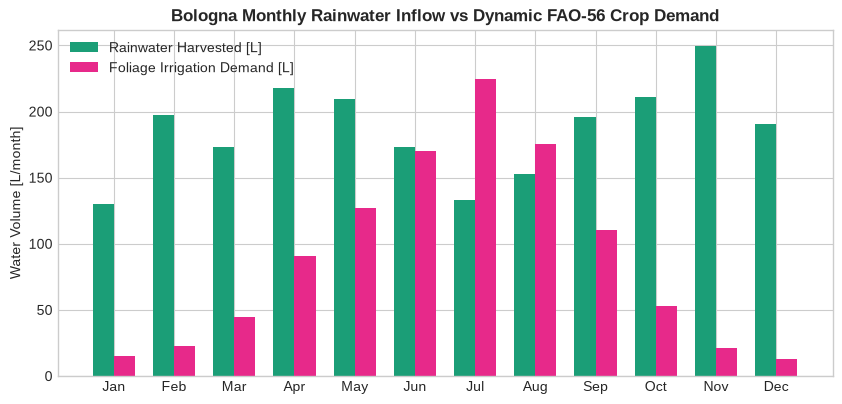

In [2]:
sim_h = simulate_hydrology_and_storage(df_w, df_crop, use_dynamic_fao56=True)
m_h = evaluate_hydrology_performance(sim_h)
for k, v in m_h.items():
    print(f"{k:<30}: {v}")

# Plot monthly water balance
monthly_rain = sim_h['rain_harvested_l'].groupby(df_w['month']).sum()
monthly_irr = sim_h['irr_required_l'].groupby(df_w['month']).sum()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(10, 4.5))
x = np.arange(12)
w = 0.35
plt.bar(x - w/2, monthly_rain, w, label="Rainwater Harvested [L]", color="#1b9e77")
plt.bar(x + w/2, monthly_irr, w, label="Foliage Irrigation Demand [L]", color="#e7298a")
plt.xticks(x, months)
plt.ylabel("Water Volume [L/month]")
plt.title("Bologna Monthly Rainwater Inflow vs Dynamic FAO-56 Crop Demand", fontweight="bold")
plt.legend()
plt.show()

### 2. Multi-Tier Micro-Irrigation Hydraulics & SpreadSheet Verification
Water is pumped from the cylindrical base reservoir ({\text{tank}} = 0.15\text{ m}^2$) through an \text{ mm}$ PE manifold to 4 vertical tiers.
Below is the verification table documenting the historical Excel Row 35 formula anomaly.

In [3]:
df_audit = compare_with_excel_hydraulic_baseline()
df_audit

,Tier,Static Head [m],Excel Value [kW],Corrected Physics [kW],Discrepancy [%],Notes
0,Tier 4 (z=4.0m),3.96,0.04995,0.04995,0.0,Exact match
1,Tier 3 (z=3.0m),2.96,0.03733,0.03733,0.0,Exact match
2,Tier 2 (z=2.0m),1.96,0.01211,0.02472,104.1,Excel formula bug (multiplied by 0.7)
3,Tier 1 (z=1.0m),0.96,0.01211,0.01211,0.0,Exact match


### 3. Dynamic Head vs Water Storage Level
As the reservoir level varies between empty (bash\text{ m}$) and full (.0\text{ m}$), static geodetic head decreases accordingly.

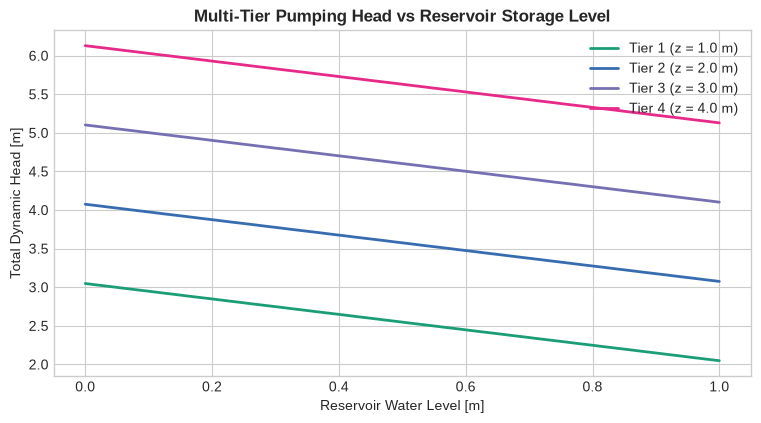

In [4]:
water_levels = np.linspace(0.0, 1.0, 50)
plt.figure(figsize=(9, 4.5))
for z, c in zip([1.0, 2.0, 3.0, 4.0], ["#1b9e77", "#386cb0", "#7570b3", "#e7298a"]):
    heads = [calculate_tier_dynamic_head(z, h)['h_total_m'] for h in water_levels]
    plt.plot(water_levels, heads, label=f"Tier {int(z)} (z = {z:.1f} m)", color=c, lw=2.0)

plt.xlabel("Reservoir Water Level [m]")
plt.ylabel("Total Dynamic Head [m]")
plt.title("Multi-Tier Pumping Head vs Reservoir Storage Level", fontweight="bold")
plt.legend()
plt.show()